# Incident Enrichment POC

**Author:** Shambhavi Shekhar

The Incident Enrichment Layer sits after the correlation engine. It takes a correlated finding and the raw Wazuh records, and builds a structured, explainable incident:

**finding → normalisation → de-duplication → context retrieval → relationship scoring → sessions and outcome → MITRE techniques → timeline → graph → incident object**

| Step | What it does |
|---|---|
| Normalisation | One record per raw line with a unique `record_uid`; event time read from the syslog line; IP / user / port parsed from the log text when Wazuh did not decode them |
| De-duplication | Wazuh writes the same line to `alerts.json` and `archives.json`; copies are merged by host + log line into canonical events with a stable `event_uid` |
| Finding | Simulated Sigma-style threshold finding built from IP-bearing alerts (a real Sigma finding can be used instead) |
| Relationship scoring | Each event in a window around the finding is scored and labelled `direct` (shares the source IP) or `inferred` (user + host + time) |
| Sessions and outcome | SSH sessions rebuilt from the process ID; attempts, how each ended, any successful login |
| MITRE techniques | Evidence status per technique (`observed` / `attempted_only`) and sub-technique → parent links |
| Outputs | Timeline, incident graph, activity heatmap, impact scope, incident object (JSON) |

In [1]:
import json
import re
import hashlib
from datetime import timedelta

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


def load_jsonl(path):
    events = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                events.append(json.loads(line))
    return events


from pathlib import Path

# Works in Colab (files uploaded next to the notebook) and inside the repo (data/sample)
DATA_DIR = Path(".") if Path("alerts.json").exists() else Path("../data/sample")
alerts = load_jsonl(DATA_DIR / "alerts.json")
archives = load_jsonl(DATA_DIR / "archives.json")

print("Alerts:", len(alerts))
print("Archives:", len(archives))

Alerts: 46
Archives: 516


## 1. Normalisation

Each raw record becomes one flat row with:
- `record_uid` — unique per raw record
- `event_time` — time written in the log line itself; `ingest_time` — when Wazuh processed it
- `program`, `pid` — which process wrote the line (used to rebuild SSH sessions)
- fallback parsing of IP / user / port from the log text, with `fields_from` saying where each value came from

In [2]:
def get_nested(data, *keys):
    current = data
    for key in keys:
        if not isinstance(current, dict):
            return None
        current = current.get(key)
    return current


SYSLOG_PREFIX = re.compile(
    r"^(?P<mon>[A-Z][a-z]{2})\s+(?P<day>\d{1,2}) (?P<time>\d{2}:\d{2}:\d{2}) "
    r"(?P<host>\S+) (?P<program>[^\[:\s]+)(?:\[(?P<pid>\d+)\])?:"
)


def parse_event_time(full_log, ingest_time):
    """Read the timestamp from the syslog line. Syslog has no year,
    so the year comes from the Wazuh ingestion timestamp."""
    if not full_log or pd.isna(ingest_time):
        return ingest_time
    m = SYSLOG_PREFIX.match(full_log)
    if not m:
        return ingest_time
    text = f"{ingest_time.year} {m['mon']} {m['day']} {m['time']}"
    t = pd.to_datetime(text, format="%Y %b %d %H:%M:%S", utc=True, errors="coerce")
    if pd.isna(t):
        return ingest_time
    # Guard against year rollover (log written in December, ingested in January)
    if t - ingest_time > timedelta(days=1):
        t = t.replace(year=t.year - 1)
    return t


# Patterns for values Wazuh's decoders did not extract
IP = r"(\d{1,3}(?:\.\d{1,3}){3})"
LOG_PATTERNS = [
    ("source_ip", re.compile(rf"from {IP} port \d+")),
    ("source_ip", re.compile(rf"authenticating user \S+ {IP} port")),
    ("source_ip", re.compile(rf"rhost={IP}")),
    ("source_port", re.compile(r"port (\d+)")),
    ("target_user", re.compile(r"authenticating user (\S+) ")),
    ("target_user", re.compile(r"(?:Failed|Accepted) \w+ for (?:invalid user )?(\S+) from")),
    ("target_user", re.compile(r"\buser=(\S+)")),
    ("target_user", re.compile(r"for user \((\S+)\)")),
]


def extract_from_log(full_log):
    found = {}
    if not full_log:
        return found
    for field, pattern in LOG_PATTERNS:
        if field in found:
            continue
        m = pattern.search(full_log)
        if m:
            found[field] = m.group(1)
    return found


def normalize_event(event, source, line_no):
    rule = event.get("rule", {}) or {}
    data = event.get("data", {}) or {}
    mitre = rule.get("mitre", {}) or {}
    techniques = mitre.get("id", [])
    if isinstance(techniques, str):
        techniques = [techniques]

    full_log = event.get("full_log")
    prefix = SYSLOG_PREFIX.match(full_log or "")

    record = {
        "record_uid": f"{source}:{line_no}",
        "source": source,
        "wazuh_id": event.get("id"),                   # kept, but NOT treated as unique
        "ingest_time": event.get("timestamp"),
        "host": get_nested(event, "agent", "name"),
        "host_ip": get_nested(event, "agent", "ip"),
        "rule_id": str(rule.get("id")) if rule.get("id") is not None else None,
        "rule_level": rule.get("level"),
        "description": rule.get("description"),
        "decoder": get_nested(event, "decoder", "name"),
        "program": prefix["program"] if prefix else get_nested(event, "predecoder", "program_name"),
        "pid": prefix["pid"] if prefix else None,
        "source_ip": data.get("srcip"),
        "source_port": data.get("srcport"),
        "target_user": data.get("dstuser") or data.get("srcuser"),
        "techniques": techniques,
        "groups": rule.get("groups", []),
        "full_log": full_log,
        "raw_event": event,
    }

    # Fill gaps from the log text, and record provenance
    parsed = extract_from_log(full_log)
    fields_from = {}
    for field in ("source_ip", "source_port", "target_user"):
        if record[field]:
            fields_from[field] = "wazuh"
        elif field in parsed:
            record[field] = parsed[field]
            fields_from[field] = "parsed_from_log"
    record["fields_from"] = fields_from
    return record


records = (
    [normalize_event(e, "alert", i) for i, e in enumerate(alerts, start=1)]
    + [normalize_event(e, "archive", i) for i, e in enumerate(archives, start=1)]
)

df = pd.DataFrame(records)
df["ingest_time"] = pd.to_datetime(df["ingest_time"], utc=True, errors="coerce")
df["event_time"] = [parse_event_time(fl, it) for fl, it in zip(df["full_log"], df["ingest_time"])]
df = df.sort_values(["event_time", "ingest_time"]).reset_index(drop=True)

print("Normalized records:", len(df))
print("Unique record_uids:", df["record_uid"].nunique())
print("Unique Wazuh ids:  ", df["wazuh_id"].nunique(), "  <- not unique, so not used as a key")

has_syslog_time = df["full_log"].fillna("").str.match(SYSLOG_PREFIX)
lag = (df.loc[has_syslog_time, "ingest_time"] - df.loc[has_syslog_time, "event_time"]).dt.total_seconds()
print(f"Records with a syslog timestamp: {int(has_syslog_time.sum())}")
print(f"Wazuh ingestion time vs. log time: median {lag.median():.1f}s later, max {lag.max():.1f}s later")

Normalized records: 562
Unique record_uids: 562
Unique Wazuh ids:   135   <- not unique, so not used as a key
Records with a syslog timestamp: 166
Wazuh ingestion time vs. log time: median 1.8s later, max 51.6s later


## 2. Canonicalisation

Wazuh writes the same log line to both `alerts.json` and `archives.json`. The duplicate is the *same log line from the same host*, so that is the key: `host | full_log`.
The syslog line already contains its own timestamp and PID, so two genuinely different events never collide.

The Wazuh timestamp is not a safe key: Wazuh processes logs in batches, so two different events can share one (the example below).

In [3]:
def canonical_key(row):
    if row["full_log"]:
        return f"{row['host']}|{row['full_log'].strip()}"
    return f"record|{row['record_uid']}"


df["canonical_key"] = df.apply(canonical_key, axis=1)
df["event_uid"] = "evt_" + df["canonical_key"].map(
    lambda k: hashlib.sha1(k.encode()).hexdigest()[:12]
)


def first_non_null(series):
    s = series.dropna()
    return s.iloc[0] if len(s) else None


def merge_dicts(series):
    merged = {}
    for d in series:
        for k, v in (d or {}).items():
            # prefer Wazuh-decoded values over parsed ones
            if merged.get(k) != "wazuh":
                merged[k] = v
    return merged


canonical = (
    df.groupby("event_uid", sort=False)
    .agg(
        event_time=("event_time", "min"),
        ingest_time=("ingest_time", "min"),
        host=("host", first_non_null),
        program=("program", first_non_null),
        pid=("pid", first_non_null),
        rule_id=("rule_id", first_non_null),
        rule_level=("rule_level", "max"),
        description=("description", first_non_null),
        decoder=("decoder", first_non_null),
        source_ip=("source_ip", first_non_null),
        source_port=("source_port", first_non_null),
        target_user=("target_user", first_non_null),
        techniques=("techniques", lambda s: sorted({t for ts in s for t in ts})),
        full_log=("full_log", first_non_null),
        fields_from=("fields_from", merge_dicts),
        sources=("source", lambda s: sorted(set(s))),
        record_uids=("record_uid", list),
        wazuh_ids=("wazuh_id", lambda s: sorted(set(x for x in s if x))),
    )
    .reset_index()
    .sort_values(["event_time", "ingest_time"])
    .reset_index(drop=True)
)
canonical["raw_record_count"] = canonical["record_uids"].map(len)

print("Raw records:      ", len(df))
print("Canonical events: ", len(canonical))

# Two different failed-password lines that Wazuh processed in the same batch stay separate
check = canonical[canonical["full_log"].fillna("").str.contains("Failed password .* port 52966", regex=True)]
print("\nFailed-password events in SSH session 1 (the logs contain 3):")
print(check[["event_time", "event_uid", "raw_record_count", "full_log"]].to_string(index=False))

Raw records:       562
Canonical events:  337

Failed-password events in SSH session 1 (the logs contain 3):
               event_time        event_uid  raw_record_count                                                                                             full_log
2026-09-21 04:03:42+00:00 evt_4b7fe5876ab3                 2 Sep 21 04:03:42 agent sshd-session[1941]: Failed password for root from 192.168.1.34 port 52966 ssh2
2026-09-21 04:03:43+00:00 evt_c33aa5048695                 2 Sep 21 04:03:43 agent sshd-session[1941]: Failed password for root from 192.168.1.34 port 52966 ssh2
2026-09-21 04:03:45+00:00 evt_bfac6c89ef82                 2 Sep 21 04:03:45 agent sshd-session[1941]: Failed password for root from 192.168.1.34 port 52966 ssh2


## 3. The finding (simulated Sigma output)

In production this comes from Ramya's Sigma engine via ClickHouse. Here we simulate what a threshold rule like *"≥ 5 authentication-failure alerts from one source IP against one host within 10 minutes"* would emit.
It is built from **alerts that carry a source IP only** — not from archives, and not from IP-less events — so the enrichment step below has to find the rest of the evidence on its own.

⚠️ The scoring below still compares events to this finding's attributes, so the relationship scores are only a real test once a genuine Sigma finding is the input.

In [4]:
SIGMA_THRESHOLD = 5
SIGMA_WINDOW = pd.Timedelta(minutes=10)

auth_fail_alerts = canonical[
    canonical["sources"].map(lambda s: "alert" in s)
    & canonical["source_ip"].notna()
    & canonical["description"].fillna("").str.contains("fail|missed", case=False)
].copy()

findings = []
for (ip, user, host), grp in auth_fail_alerts.groupby(["source_ip", "target_user", "host"]):
    grp = grp.sort_values("event_time")
    span = grp["event_time"].max() - grp["event_time"].min()
    if len(grp) >= SIGMA_THRESHOLD and span <= SIGMA_WINDOW:
        findings.append({
            "finding_id": "finding-sim-001",
            "finding_source": "simulated_sigma_threshold",   # label it honestly
            "rule": f">= {SIGMA_THRESHOLD} auth-failure alerts per source IP within {int(SIGMA_WINDOW.total_seconds() // 60)} min",
            "title": "Repeated SSH authentication failures",
            "source_ip": ip,
            "target_user": user,
            "target_host": host,
            "first_seen": grp["event_time"].min(),
            "last_seen": grp["event_time"].max(),
            "matched_alert_count": len(grp),
            "techniques": sorted({t for ts in grp["techniques"] for t in ts}),
            "matched_event_uids": grp["event_uid"].tolist(),
        })

finding = findings[0]
for k, v in finding.items():
    if k != "matched_event_uids":
        print(f"{k:22} {v}")

finding_id             finding-sim-001
finding_source         simulated_sigma_threshold
rule                   >= 5 auth-failure alerts per source IP within 10 min
title                  Repeated SSH authentication failures
source_ip              192.168.1.34
target_user            root
target_host            agent
first_seen             2026-09-21 04:03:41+00:00
last_seen              2026-09-21 04:06:32+00:00
matched_alert_count    9
techniques             ['T1021.004', 'T1110', 'T1110.001']


## 4. Context retrieval and relationship scoring

Events within ±1 minute of the finding are scored against it (same IP +3, user +2, host +2, shared technique +2, inside the finding window +1; 5 or more = part of the incident). In addition:
- every related event is labelled `direct` (shares the finding's source IP) or `inferred` (linked only by user + host + time).
- Events on the same host from the SSH service itself (e.g. *"Server listening on port 22"*) are kept as **service context** instead of background.

In [5]:
CONTEXT_PAD = pd.Timedelta(minutes=1)
RELATED_EVENT_THRESHOLD = 5

ctx_start = finding["first_seen"] - CONTEXT_PAD
ctx_end = finding["last_seen"] + CONTEXT_PAD

context = canonical[
    (canonical["event_time"] >= ctx_start) & (canonical["event_time"] <= ctx_end)
].copy()


def calculate_relationship(event, finding):
    score, reasons = 0, []
    if event["source_ip"] and event["source_ip"] == finding["source_ip"]:
        score += 3; reasons.append("same_source_ip")
    if event["target_user"] and event["target_user"] == finding["target_user"]:
        score += 2; reasons.append("same_target_user")
    if event["host"] and event["host"] == finding["target_host"]:
        score += 2; reasons.append("same_target_host")
    if set(event["techniques"]) & set(finding["techniques"]):
        score += 2; reasons.append("shared_mitre_technique")
    if finding["first_seen"] <= event["event_time"] <= finding["last_seen"]:
        score += 1; reasons.append("inside_finding_window")
    return score, reasons


SSH_PROGRAMS = {"sshd", "sshd-session"}

scored = context.apply(lambda r: calculate_relationship(r, finding), axis=1)
context["relationship_score"] = [s for s, _ in scored]
context["relationship_reasons"] = [r for _, r in scored]


def role_of(row):
    if row["relationship_score"] >= RELATED_EVENT_THRESHOLD:
        return "incident"
    if row["host"] == finding["target_host"] and row["program"] in SSH_PROGRAMS:
        return "service_context"
    return "background"


context["role"] = context.apply(role_of, axis=1)
context["link_type"] = context.apply(
    lambda r: None if r["role"] != "incident"
    else ("direct" if "same_source_ip" in r["relationship_reasons"] else "inferred"),
    axis=1,
)

print("Context events:", len(context))
print(context["role"].value_counts().to_string())
print("\nLink types among incident events:")
print(context.loc[context["role"] == "incident", "link_type"].value_counts().to_string())
print("\nService context:")
for _, r in context[context["role"] == "service_context"].iterrows():
    print("  ", r["event_time"].strftime("%H:%M:%S"), r["full_log"])

Context events: 26
role
incident           17
background          7
service_context     2

Link types among incident events:
link_type
direct      12
inferred     5

Service context:
   04:03:38 Sep 21 04:03:38 agent sshd[1939]: Server listening on 0.0.0.0 port 22.
   04:03:38 Sep 21 04:03:38 agent sshd[1939]: Server listening on :: port 22.


## 5. Sessions and outcome

An analyst's first question is *"did they get in?"*

Each SSH connection is handled by one `sshd-session` process, so its **PID identifies the session**. `unix_chkpwd` runs as a separate child process, so it is attached to the session whose time range covers it (an *inferred* link).
Outcome rules:
- a line like `Accepted password for …` → **success**
- `Connection closed by authenticating user … [preauth]` or `Disconnected … [preauth]` without a success → **failed, client disconnected**
- neither → **unknown** (session may still be open)

In [6]:
incident = context[context["role"] == "incident"].copy().sort_values("event_time").reset_index(drop=True)

is_session_line = incident["program"] == "sshd-session"
sessions = {}
for pid, grp in incident[is_session_line].groupby("pid"):
    logs = grp["full_log"].fillna("")
    failed = int(logs.str.contains(r"Failed \w+ for").sum())
    accepted = int(logs.str.contains(r"Accepted \w+ for").sum())
    closed = bool(logs.str.contains(r"\[preauth\]").any())
    if accepted:
        outcome = "success"
    elif closed:
        outcome = "failed_client_disconnected"
    else:
        outcome = "unknown"
    sessions[pid] = {
        "pid": pid,
        "start": grp["event_time"].min(),
        "end": grp["event_time"].max(),
        "source_ip": first_non_null(grp["source_ip"]),
        "source_port": first_non_null(grp["source_port"]),
        "target_user": first_non_null(grp["target_user"]),
        "failed_attempts": failed,
        "successful_logins": accepted,
        "outcome": outcome,
    }

session_list = sorted(sessions.values(), key=lambda s: s["start"])
for i, s in enumerate(session_list, start=1):
    s["session_ref"] = f"S{i}"


def assign_session(row):
    if row["program"] == "sshd-session":
        return sessions[row["pid"]]["session_ref"]
    for s in session_list:  # inferred: child process inside the session's time range
        if s["start"] - pd.Timedelta(seconds=2) <= row["event_time"] <= s["end"] + pd.Timedelta(seconds=2):
            return s["session_ref"]
    return None


incident["session_ref"] = incident.apply(assign_session, axis=1)
incident["event_ref"] = [f"E{i}" for i in range(1, len(incident) + 1)]

# Look in ALL available data (not only the window) for a later success from this IP
success_anywhere = df[
    df["full_log"].fillna("").str.contains(r"Accepted \w+ for", regex=True)
    & (df["source_ip"] == finding["source_ip"])
]

outcome = {
    "sessions": len(session_list),
    "failed_password_attempts": sum(s["failed_attempts"] for s in session_list),
    "successful_logins": int(len(success_anywhere)),
    "status": "no_successful_authentication_observed" if success_anywhere.empty else "successful_authentication_observed",
    "observed_until": str(df["event_time"].max()),
    "note": "Absence of evidence only covers the logs available up to observed_until.",
}

print("Sessions:")
for s in session_list:
    gap = ""
    print(f"  {s['session_ref']}  pid={s['pid']}  {s['start'].strftime('%H:%M:%S')}–{s['end'].strftime('%H:%M:%S')}  "
          f"port={s['source_port']}  failed={s['failed_attempts']}  outcome={s['outcome']}")
if len(session_list) > 1:
    for a, b in zip(session_list, session_list[1:]):
        print(f"  gap {a['session_ref']} → {b['session_ref']}: {(b['start'] - a['end']).total_seconds():.0f} s")
print("\nOutcome:", json.dumps(outcome, indent=2))

Sessions:
  S1  pid=1941  04:03:41–04:03:45  port=52966  failed=3  outcome=failed_client_disconnected
  S2  pid=1945  04:06:14–04:06:32  port=52983  failed=3  outcome=failed_client_disconnected
  gap S1 → S2: 149 s

Outcome: {
  "sessions": 2,
  "failed_password_attempts": 6,
  "successful_logins": 0,
  "status": "no_successful_authentication_observed",
  "observed_until": "2026-09-21 04:30:21.986000+00:00",
  "note": "Absence of evidence only covers the logs available up to observed_until."
}


## 6. MITRE techniques with evidence status

Wazuh rule 5760 tags every failed SSH login with **T1021.004 (Remote Services: SSH — Lateral Movement)**. Lateral movement needs a *working* remote session; with zero successful logins it was only attempted. Each technique carries a status, and sub-techniques point to their parent.

In [7]:
TECHNIQUE_INFO = {
    "T1110": {"name": "Brute Force", "tactic": "Credential Access", "parent": None},
    "T1110.001": {"name": "Password Guessing", "tactic": "Credential Access", "parent": "T1110"},
    "T1021.004": {"name": "Remote Services: SSH", "tactic": "Lateral Movement", "parent": "T1021"},
}

technique_assessment = []
for t in sorted({t for ts in incident["techniques"] for t in ts}):
    info = TECHNIQUE_INFO.get(t, {"name": None, "tactic": None, "parent": None})
    evidence = incident.loc[incident["techniques"].map(lambda ts: t in ts), "event_ref"].tolist()
    if info["tactic"] == "Lateral Movement" and outcome["successful_logins"] == 0:
        status = "attempted_only"
        why = "Tagged by Wazuh rule mapping, but no successful remote session was observed."
    else:
        status = "observed"
        why = "Directly supported by the evidence events."
    technique_assessment.append({"technique": t, **info, "status": status,
                                 "evidence_events": evidence, "reason": why})

print(pd.DataFrame(technique_assessment)[["technique", "name", "tactic", "parent", "status", "evidence_events"]].to_string(index=False))

technique                 name            tactic parent         status                                            evidence_events
T1021.004 Remote Services: SSH  Lateral Movement  T1021 attempted_only                                [E3, E4, E6, E11, E13, E15]
    T1110          Brute Force Credential Access    NaN       observed                                                      [E16]
T1110.001    Password Guessing Credential Access  T1110       observed [E1, E2, E3, E4, E5, E6, E9, E10, E11, E12, E13, E14, E15]


## 7. Timeline

Ordered by `event_time`. Each row shows its session, whether its link to the finding is direct or inferred, and how many raw records were merged into it.

In [8]:
def short_text(row):
    if pd.notna(row["description"]) and row["description"]:
        return row["description"]
    log = row["full_log"] or ""
    m = SYSLOG_PREFIX.match(log)
    return (log[m.end():].strip() if m else log)[:70]


incident["summary"] = incident.apply(short_text, axis=1)

timeline_view = incident[[
    "event_ref", "event_time", "session_ref", "program", "rule_id", "rule_level",
    "summary", "link_type", "relationship_score", "raw_record_count",
]].copy()
timeline_view["event_time"] = timeline_view["event_time"].dt.strftime("%H:%M:%S")
timeline_view["rule_level"] = timeline_view["rule_level"].astype("Int64")
timeline_view = timeline_view.fillna({"rule_id": "-"})
print(timeline_view.to_string(index=False))

print(f"\nIncident events: {len(incident)}")
print(f"  of which session-closing lines found by log parsing: {int(incident['summary'].str.contains('Connection closed').sum())}")
print("Raw records behind them:", int(incident["raw_record_count"].sum()))

event_ref event_time session_ref      program rule_id  rule_level                                                                summary link_type  relationship_score  raw_record_count
       E1   04:03:41          S1  unix_chkpwd    5557           5                                    unix_chkpwd: Password check failed.  inferred                   7                 2
       E2   04:03:41          S1 sshd-session    5503           5                                                PAM: User login failed.    direct                  10                 2
       E3   04:03:42          S1 sshd-session    5760           5                                           sshd: authentication failed.    direct                  10                 2
       E4   04:03:43          S1 sshd-session    5760           5                                           sshd: authentication failed.    direct                  10                 2
       E5   04:03:43          S1  unix_chkpwd    5557           5          

## 8. Incident graph

Structure: **incident → sessions → events**, and the IP / user / host attach to the **sessions**. Events sit in one row per session, so a line between rows always means something (here: the gap between the two sessions).
Edge styles in the legend are generated from the same style table used to draw them.

The saved graph keeps every edge (including each event → technique link). The *picture* simplifies: membership in a session is shown by the row, and event → technique links are drawn once from the incident, with per-session counts in each technique label (`S1×6` = six events in session 1). Hollow event circles are **inferred** links.

In [9]:
G = nx.DiGraph()
inc_id = finding["finding_id"]

G.add_node(inc_id, kind="incident", label="Incident")
G.add_node(f"ip:{finding['source_ip']}", kind="entity", label=finding["source_ip"])
G.add_node(f"user:{finding['target_user']}", kind="entity", label=f"user: {finding['target_user']}")
G.add_node(f"host:{finding['target_host']}", kind="entity", label=f"host: {finding['target_host']}")

for s in session_list:
    sid = s["session_ref"]
    G.add_node(sid, kind="session", label=f"{sid}\n{s['failed_attempts']} failed")
    G.add_edge(inc_id, sid, rel="contains", style="semantic")
    G.add_edge(f"ip:{s['source_ip']}", sid, rel="initiated", style="semantic")
    G.add_edge(sid, f"user:{s['target_user']}", rel="targeted", style="semantic")
    G.add_edge(sid, f"host:{finding['target_host']}", rel="on_host", style="semantic")

for _, e in incident.iterrows():
    G.add_node(e["event_uid"], kind="event", label=e["event_ref"])
    if e["session_ref"]:
        G.add_edge(e["session_ref"], e["event_uid"], rel="contains",
                   style="inferred" if e["link_type"] == "inferred" else "semantic")
    for t in e["techniques"]:
        G.add_node(f"t:{t}", kind="technique", label=t)
        G.add_edge(e["event_uid"], f"t:{t}", rel="mapped_to", style="semantic")

for t in technique_assessment:
    if t["parent"] and f"t:{t['parent']}" in G:
        G.add_edge(f"t:{t['technique']}", f"t:{t['parent']}", rel="subtechnique_of", style="semantic")

# temporal edges only WITHIN a session, plus one session-to-session edge
for sref, grp in incident.groupby("session_ref"):
    uids = grp.sort_values("event_time")["event_uid"].tolist()
    for a, b in zip(uids, uids[1:]):
        G.add_edge(a, b, rel="precedes", style="temporal")
for a, b in zip(session_list, session_list[1:]):
    G.add_edge(a["session_ref"], b["session_ref"], rel="followed_by",
               gap_seconds=(b["start"] - a["end"]).total_seconds(), style="temporal")

print("Nodes:", G.number_of_nodes(), " Edges:", G.number_of_edges())

Nodes: 26  Edges: 62


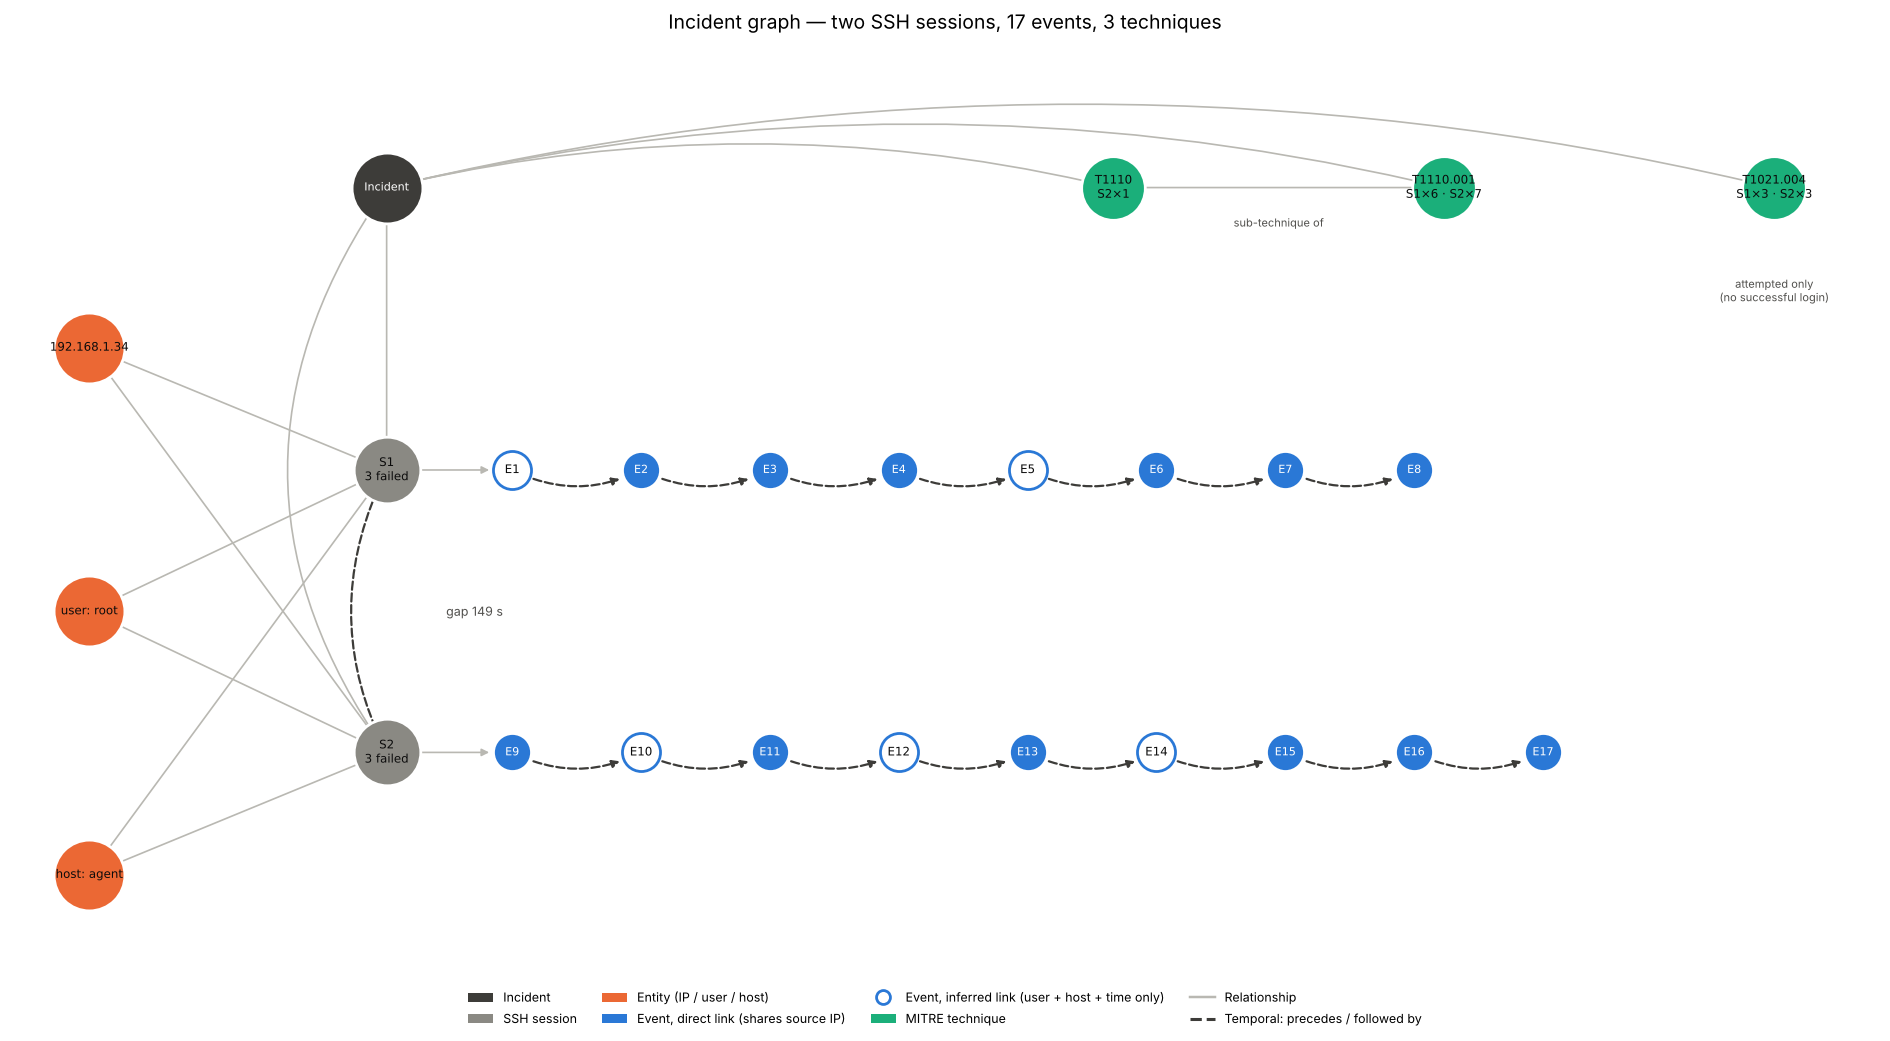

In [10]:
# Drawing view. The full graph G (saved in the incident object) keeps every edge;
# the picture simplifies two things so it stays readable:
#   - session -> event membership is shown by the ROW, not by 17 extra lines
#   - event -> technique edges are drawn once from the incident; per-session counts are in the node label
# Colours: reference categorical palette slots 1-3 + neutrals (identity is also given by labels)
NODE_STYLE = {
    "incident":  {"color": "#3d3c39", "size": 2600, "label": "Incident"},
    "session":   {"color": "#8a8983", "size": 2300, "label": "SSH session"},
    "entity":    {"color": "#eb6834", "size": 2600, "label": "Entity (IP / user / host)"},
    "event":     {"color": "#2a78d6", "size": 750,  "label": "Event, direct link (shares source IP)"},
    "technique": {"color": "#1baf7a", "size": 2100, "label": "MITRE technique"},
}
INFERRED_EVENT = {"label": "Event, inferred link (user + host + time only)"}
EDGE_STYLE = {
    "semantic": {"color": "#b9b8b2", "style": "solid",  "width": 1.2, "label": "Relationship"},
    "temporal": {"color": "#3d3c39", "style": "dashed", "width": 1.6, "label": "Temporal: precedes / followed by"},
}

D = nx.DiGraph()
for n, d in G.nodes(data=True):
    D.add_node(n, **d)
for u, v, d in G.edges(data=True):
    if d["rel"] == "contains" and G.nodes[v]["kind"] == "event":
        # draw only the link to the session's first event; the row shows the rest
        first_uid = incident.loc[incident["session_ref"] == u].sort_values("event_time")["event_uid"].iloc[0]
        if v != first_uid:
            continue
    if d["rel"] == "mapped_to":
        continue
    D.add_edge(u, v, **{**d, "style": "temporal" if d["style"] == "temporal" else "semantic"})

tech_counts = {}
for _, e in incident.iterrows():
    for t in e["techniques"]:
        key = (e["session_ref"], f"t:{t}")
        tech_counts[key] = tech_counts.get(key, 0) + 1
for tnode in sorted({tn for (_, tn) in tech_counts}):
    D.add_edge(inc_id, tnode, rel="uses_technique", style="semantic")

inferred_events = set(incident.loc[incident["link_type"] == "inferred", "event_uid"])

pos = {}
pos[inc_id] = (-9.5, 4.6)
pos[f"ip:{finding['source_ip']}"] = (-14.0, 2.9)
pos[f"user:{finding['target_user']}"] = (-14.0, 0.1)
pos[f"host:{finding['target_host']}"] = (-14.0, -2.7)
tech_order = ["t:T1110", "t:T1110.001", "t:T1021.004"]
tech_x = [1.5, 6.5, 11.5]
for n, x in zip([t for t in tech_order if t in D], tech_x):
    pos[n] = (x, 4.6)

# technique labels carry the per-session counts instead of edge labels
for n, d in D.nodes(data=True):
    if d["kind"] == "technique":
        parts = [f"{sref}×{cnt}" for (sref, tn), cnt in sorted(tech_counts.items()) if tn == n]
        D.nodes[n]["label"] = f"{d['label']}\n" + " · ".join(parts)

for row_i, s in enumerate(session_list):
    y = 1.6 - row_i * 3.0
    pos[s["session_ref"]] = (-9.5, y)
    evs = incident[incident["session_ref"] == s["session_ref"]].sort_values("event_time")
    for j, uid in enumerate(evs["event_uid"]):
        pos[uid] = (-7.6 + j * 1.95, y)

fig, ax = plt.subplots(figsize=(19, 10.5))
first_session = session_list[0]["session_ref"]
for u, v, d in D.edges(data=True):
    st = EDGE_STYLE[d["style"]]
    if d["style"] == "temporal":
        cs = "arc3,rad=0.25"
    elif d["rel"] == "uses_technique":
        cs = "arc3,rad=-0.12"   # arc over the technique row
    elif d["rel"] == "contains" and u == inc_id and v != first_session:
        cs = "arc3,rad=0.35"   # bow around S1 instead of running through it
    else:
        cs = "arc3"
    nx.draw_networkx_edges(D, pos, edgelist=[(u, v)], ax=ax, edge_color=st["color"], style=st["style"],
                           width=st["width"], arrows=True, arrowsize=11, node_size=1100,
                           connectionstyle=cs)

for kind, st in NODE_STYLE.items():
    nodes = [n for n, d in D.nodes(data=True) if d["kind"] == kind and n not in inferred_events]
    nx.draw_networkx_nodes(D, pos, nodelist=nodes, node_color=st["color"], node_size=st["size"],
                           edgecolors="white", linewidths=2, ax=ax)
nx.draw_networkx_nodes(D, pos, nodelist=list(inferred_events), node_color="white",
                       node_size=NODE_STYLE["event"]["size"], edgecolors=NODE_STYLE["event"]["color"],
                       linewidths=2, ax=ax)

labels = {n: d["label"] for n, d in D.nodes(data=True)}
white_text = {n for n, d in D.nodes(data=True)
              if d["kind"] in ("incident", "event") and n not in inferred_events}
nx.draw_networkx_labels(D, pos, {n: l for n, l in labels.items() if n in white_text},
                        font_size=8, font_color="white", ax=ax)
nx.draw_networkx_labels(D, pos, {n: l for n, l in labels.items() if n not in white_text},
                        font_size=8.5, font_color="#0b0b0b", ax=ax)

x1, y1 = pos["t:T1110.001"]; x2, y2 = pos["t:T1110"]
ax.text((x1 + x2) / 2, y1 - 0.3, "sub-technique of", ha="center", va="top", fontsize=8, color="#52514e")

for a, b in zip(session_list, session_list[1:]):
    (x1, y1), (x2, y2) = pos[a["session_ref"]], pos[b["session_ref"]]
    ax.text(x1 + 0.9, (y1 + y2) / 2, f"gap {(b['start'] - a['end']).total_seconds():.0f} s",
            ha="left", va="center", fontsize=9, color="#52514e")
for t in technique_assessment:
    if t["status"] == "attempted_only":
        x, y = pos[f"t:{t['technique']}"]
        ax.text(x, y - 0.95, "attempted only\n(no successful login)", ha="center", va="top",
                fontsize=8, color="#52514e")

handles = [Patch(facecolor=st["color"], label=st["label"]) for st in NODE_STYLE.values()]
handles.insert(4, Line2D([0], [0], marker="o", color="none", markerfacecolor="white",
                         markeredgecolor=NODE_STYLE["event"]["color"], markeredgewidth=2,
                         markersize=10, label=INFERRED_EVENT["label"]))
handles += [Line2D([0], [0], color=st["color"], linestyle=st["style"], linewidth=st["width"] + 0.6,
                   label=st["label"]) for st in EDGE_STYLE.values()]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.01), fontsize=9,
          frameon=False, ncol=4)
ax.set_title("Incident graph — two SSH sessions, 17 events, 3 techniques", fontsize=14)
# set limits from node positions (curved edge patches can confuse matplotlib's autoscaling)
xs = [x for x, _ in pos.values()]; ys = [y for _, y in pos.values()]
ax.set_xlim(min(xs) - 1.2, max(xs) + 1.6)
ax.set_ylim(min(ys) - 1.0, max(ys) + 1.6)
ax.axis("off")
plt.tight_layout()
plt.savefig("incident_graph.png", dpi=130, bbox_inches="tight")
plt.show()

## 9. Activity heatmap and attempt-level summary

Every minute between the first and last event is shown (empty minutes included), and the colour scale uses whole numbers. Below it, the summary an analyst actually wants: sessions, attempts, outcome.

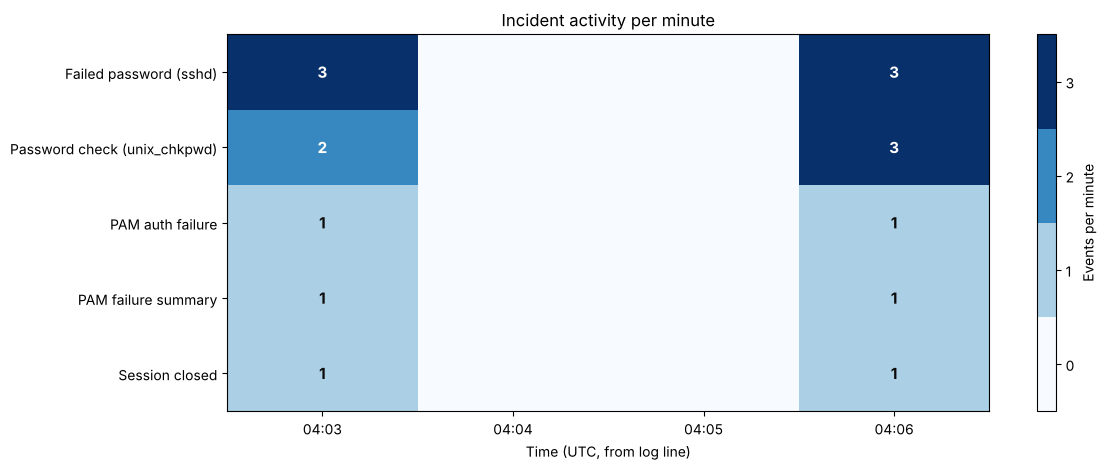

session              time             source user  failed attempts  successful logins                      ended
     S1 04:03:41–04:03:45 192.168.1.34:52966 root                3                  0 failed_client_disconnected
     S2 04:06:14–04:06:32 192.168.1.34:52983 root                3                  0 failed_client_disconnected

Total: 2 sessions, 6 failed password attempts, 0 successful logins → no_successful_authentication_observed


In [11]:
def activity_category(row):
    text = f"{row['description'] or ''} {row['full_log'] or ''}".lower()
    if "failed password" in text:
        return "Failed password (sshd)"
    if "password check failed" in text:
        return "Password check (unix_chkpwd)"
    if "pam_unix(sshd:auth): authentication failure" in text:
        return "PAM auth failure"
    if "more authentication failure" in text:
        return "PAM failure summary"
    if "connection closed" in text or "disconnected" in text:
        return "Session closed"
    return "Other SSH activity"


incident["activity"] = incident.apply(activity_category, axis=1)
incident["minute"] = incident["event_time"].dt.floor("1min")

all_minutes = pd.date_range(incident["minute"].min(), incident["minute"].max(), freq="1min")
order = ["Failed password (sshd)", "Password check (unix_chkpwd)", "PAM auth failure",
         "PAM failure summary", "Session closed", "Other SSH activity"]
heat = (pd.crosstab(incident["activity"], incident["minute"])
        .reindex(columns=all_minutes, fill_value=0)
        .reindex([o for o in order if o in set(incident["activity"])]))

vmax = int(heat.values.max())
cmap = plt.get_cmap("Blues", vmax + 1)
fig, ax = plt.subplots(figsize=(12, 4.8))
im = ax.imshow(heat.values, aspect="auto", cmap=cmap, vmin=-0.5, vmax=vmax + 0.5)
ax.set_xticks(range(len(all_minutes)), [m.strftime("%H:%M") for m in all_minutes])
ax.set_yticks(range(len(heat.index)), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = int(heat.iloc[i, j])
        if v:
            ax.text(j, i, str(v), ha="center", va="center", fontsize=11, fontweight="bold",
                    color="white" if v > vmax / 2 else "#0b0b0b")
cbar = fig.colorbar(im, ticks=range(vmax + 1))
cbar.set_label("Events per minute")
ax.set_xlabel("Time (UTC, from log line)")
ax.set_title("Incident activity per minute")
plt.tight_layout()
plt.savefig("activity_heatmap.png", dpi=130, bbox_inches="tight")
plt.show()

summary = pd.DataFrame([{
    "session": s["session_ref"],
    "time": f"{s['start'].strftime('%H:%M:%S')}–{s['end'].strftime('%H:%M:%S')}",
    "source": f"{s['source_ip']}:{s['source_port']}",
    "user": s["target_user"],
    "failed attempts": s["failed_attempts"],
    "successful logins": s["successful_logins"],
    "ended": s["outcome"],
} for s in session_list])
print(summary.to_string(index=False))
print(f"\nTotal: {outcome['sessions']} sessions, {outcome['failed_password_attempts']} failed password attempts, "
      f"{outcome['successful_logins']} successful logins → {outcome['status']}")

## 10. Impact scope

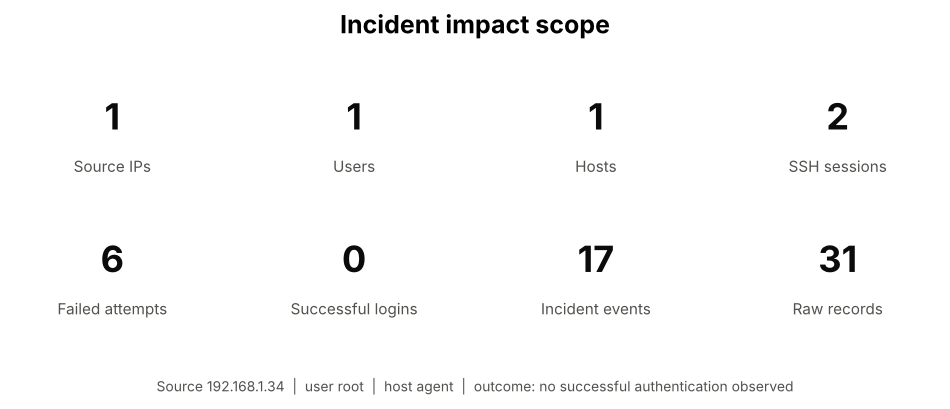

In [12]:
blast_radius = {
    "source_ips": sorted(set(incident["source_ip"].dropna())),
    "users": sorted(set(incident["target_user"].dropna())),
    "hosts": sorted(set(incident["host"].dropna())),
    "techniques_observed": [t["technique"] for t in technique_assessment if t["status"] == "observed"],
    "techniques_attempted_only": [t["technique"] for t in technique_assessment if t["status"] == "attempted_only"],
}

metrics = [
    ("Source IPs", len(blast_radius["source_ips"])),
    ("Users", len(blast_radius["users"])),
    ("Hosts", len(blast_radius["hosts"])),
    ("SSH sessions", outcome["sessions"]),
    ("Failed attempts", outcome["failed_password_attempts"]),
    ("Successful logins", outcome["successful_logins"]),
    ("Incident events", len(incident)),
    ("Raw records", int(incident["raw_record_count"].sum())),
]

fig, ax = plt.subplots(figsize=(12, 5))
ax.axis("off")
ax.text(0.5, 0.95, "Incident impact scope", ha="center", fontsize=18, fontweight="bold")
for i, (label, value) in enumerate(metrics):
    x = 0.11 + (i % 4) * 0.26
    y = 0.62 if i < 4 else 0.25
    ax.text(x, y + 0.08, str(value), ha="center", fontsize=26, fontweight="bold", color="#0b0b0b")
    ax.text(x, y - 0.03, label, ha="center", fontsize=11, color="#52514e")
ax.text(0.5, 0.02,
        f"Source {', '.join(blast_radius['source_ips'])}  |  user {', '.join(blast_radius['users'])}  |  "
        f"host {', '.join(blast_radius['hosts'])}  |  outcome: {outcome['status'].replace('_', ' ')}",
        ha="center", fontsize=10, color="#52514e")
plt.savefig("impact_scope.png", dpi=130, bbox_inches="tight")
plt.show()

## 11. Incident object

Every event is referenced by its stable `event_uid`, which lists the `record_uids` it was built from.
The `status`, `closed_at` and `watch_until` fields are reserved for tracking the incident lifecycle.

In [13]:
def iso(t):
    return None if t is None or pd.isna(t) else pd.Timestamp(t).isoformat()


incident_object = {
    "schema_version": "0.1",
    "incident_id": "INC-" + hashlib.sha1(finding["finding_id"].encode()).hexdigest()[:8].upper(),
    "status": "open",
    "closed_at": None,
    "watch_until": None,
    "finding": {
        **{k: v for k, v in finding.items() if k not in ("first_seen", "last_seen")},
        "first_seen": iso(finding["first_seen"]),
        "last_seen": iso(finding["last_seen"]),
    },
    "outcome": outcome,
    "sessions": [{**s, "start": iso(s["start"]), "end": iso(s["end"])} for s in session_list],
    "entities": {k: blast_radius[k] for k in ("source_ips", "users", "hosts")},
    "techniques": technique_assessment,
    "timeline": [
        {
            "event_ref": r["event_ref"],
            "event_uid": r["event_uid"],
            "event_time": iso(r["event_time"]),
            "ingest_time": iso(r["ingest_time"]),
            "session_ref": r["session_ref"],
            "program": r["program"],
            "rule_id": r["rule_id"],
            "rule_level": None if pd.isna(r["rule_level"]) else int(r["rule_level"]),
            "summary": r["summary"],
            "source_ip": r["source_ip"],
            "target_user": r["target_user"],
            "techniques": r["techniques"],
            "link_type": r["link_type"],
            "relationship_score": int(r["relationship_score"]),
            "relationship_reasons": r["relationship_reasons"],
            "fields_from": r["fields_from"],
            "sources": r["sources"],
            "record_uids": r["record_uids"],
        }
        for _, r in incident.iterrows()
    ],
    "service_context": [
        {"event_uid": r["event_uid"], "event_time": iso(r["event_time"]), "log": r["full_log"]}
        for _, r in context[context["role"] == "service_context"].iterrows()
    ],
    "graph": {
        "nodes": [{"id": n, **d} for n, d in G.nodes(data=True)],
        "edges": [{"source": u, "target": v, **d} for u, v, d in G.edges(data=True)],
    },
    "evidence": {
        "incident_event_count": len(incident),
        "raw_record_count": int(incident["raw_record_count"].sum()),
        "context_event_count": len(context),
        "event_uids": incident["event_uid"].tolist(),
    },
}

incident_object["evidence_summary"] = (
    f"{outcome['failed_password_attempts']} failed SSH password attempts for user "
    f"{finding['target_user']} from {finding['source_ip']} on host {finding['target_host']}, "
    f"in {outcome['sessions']} sessions between {finding['first_seen'].strftime('%H:%M:%S')} and "
    f"{finding['last_seen'].strftime('%H:%M:%S')} UTC. Each session was closed by the client before "
    f"authenticating; no successful login from this source was observed in the available logs. "
    f"The SSH service on the host started {(finding['first_seen'] - context.loc[context['role']=='service_context','event_time'].min()).total_seconds():.0f} s before the first attempt."
)

uids = incident_object["evidence"]["event_uids"]
assert len(uids) == len(set(uids)), "event_uids must be unique"

with open("incident.json", "w", encoding="utf-8") as f:
    json.dump(incident_object, f, indent=2, default=str)

print("Saved incident.json")
print("Incident:", incident_object["incident_id"])
print("Events:", len(uids), "(all unique)")
print("\n" + incident_object["evidence_summary"])

Saved incident.json
Incident: INC-DC1CEACF
Events: 17 (all unique)

6 failed SSH password attempts for user root from 192.168.1.34 on host agent, in 2 sessions between 04:03:41 and 04:06:32 UTC. Each session was closed by the client before authenticating; no successful login from this source was observed in the available logs. The SSH service on the host started 3 s before the first attempt.


## Known limitations

- **Simulated finding.** Relationship scores compare events to the finding's own attributes, so they become a real test only once a genuine Sigma finding from ClickHouse is the input.
- **Hand-picked weights** (+3 / +2 / +2 / +2 / +1, threshold 5). Next step: learn them from a labelled set of scenarios.
- **One scenario** (one IP, one user, one host). Results should be repeated on more scenarios before drawing conclusions.
- **Session ↔ `unix_chkpwd` link is inferred by time.** It's correct here, but it's a heuristic and is labelled as such.